# Tuning initial α/β: `resolve_initial_α_β`

Demonstrates `resolve_initial_α_β` (`src/tune_regularization.jl`): given `rechp.α_init`/`β_init`
set to `:auto`, it samples a single random object/noise draw (held fixed throughout), then runs an
NLopt search in log-space to find the `α`/`β` that minimize that one object's reconstruction error
-- using the exact same adjoint/Hessian machinery (`build_hessian_operator_distributed`, `minres!`)
already validated for the main outer optimization, just without the geoms-gradient or Adam update.
Same `php`/`imghp`/`opthp` as `scripts/endtoend_opt.jl` (including the `UniformlyRandomObject` and
`geoms_init_type = "monochromatic"` now in use there), except `rechp.α_init = rechp.β_init = :auto`
here, since that's the whole point of this notebook.

In [1]:
cd("../../End2EndThermalImg")
import Pkg
Pkg.activate(".")

  Activating project at `~/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg`


In [2]:
using Revise
using End2EndThermalImg
using PythonPlot
using Parameters
using Distributed
using LinearAlgebra
using Statistics

## Setup

In [3]:
@time nw = End2EndThermalImg.setup_cluster_workers()
println("nworkers = ", nworkers(), "  workers = ", workers())
println("threads per worker = ", [remotecall_fetch(Threads.nthreads, p) for p in workers()])

      From worker 5:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 5:	└   lock_file = "/Users/sophiefisher/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg/.CondaPkg/lock"
      From worker 4:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 4:	└   lock_file = "/Users/sophiefisher/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg/.CondaPkg/lock"
      From worker 6:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 6:	└   lock_file = "/Users/sophiefisher/MIT Dropbox/Sophie Fisher/Grad_School/3D-Thermal-Imaging/End2EndThermalImg/.CondaPkg/lock"
      From worker 3:	┌ Info: CondaPkg: Waiting for lock to be freed. You may delete this file if no other process is resolving.
      From worker 3:	└   lock_file = "/Us

In [4]:
# Same hyperparameters as scripts/endtoend_opt.jl, except α_init/β_init = :auto (the whole point
# of this notebook) in place of literal values.
@time @everywhere begin
    php = PhysicsHyperParams(
        λlb_μm = 8.0,
        λub_μm = 12.0,
        freq_order = 20,
        focal_length_μm = 2.0e4,
        num_unit_cells = 2048,
        unit_cell_length_μm = 4.0,
        pillar_width_lb_μm = 1.8,
        pillar_width_ub_μm = 2.7,
        pillar_width_order = 160,
        pillar_height_μm = 10.0,
        pillar_material = "Si_no_absorption",
        substrate_height_μm = 300.0,
        substrate_material = "Si_no_absorption",
        nG = 1000
    )

    imghp = ImagingHyperParams(
        objN = 32,
        imgN = 128,
        binN = 3,
        sampleN = 1,
        PSF_zlb_μm = -2.1e6,
        PSF_zub_μm = -0.9e6,
        PSF_zlen = 3,
        smoothness_order = 3.0,
        object_type = UniformlyRandomObject(Tlb = 136.15, Tub = 450.15, zlb_μm = -2.0e6, zub_μm = -1.0e6, zlen = 7, php = php),
        noise_type = RelativeNoise(0.2),
        php = php
    )

    opthp = OptimizeHyperParams(
        geoms_init_type = "monochromatic",
        maxeval = 10,
        learning_rate = 1e-3,
        save_every = 3
    )

    rechp = ReconstructionHyperParams(
        object_init_type = "uniform_offset",
        T_background = 293.15,
        z_middle_μm = -1.5e6,
        algorithm = :LD_LBFGS,
        α_init = :auto,
        β_init = :auto,
        maxeval = 2000,
        xtol_rel = 0.0,
        ftol_rel = 0.0,
        ftol_abs = 0.0,
        php = php
    )

    jhp = JobHyperParams(
        php = php,
        imghp = imghp,
        opthp = opthp,
        rechp = rechp
    )
end

  0.150483 seconds (102.62 k allocations: 5.591 MiB, 38.92% compilation time)


In [5]:
@time End2EndThermalImg.compute_system_parameters(php, imghp)

[ Info: Computing system parameters
[ Info: Image pixel size = 12.0 μm


  0.518515 seconds (2.22 M allocations: 111.987 MiB, 1.67% gc time, 106.21% compilation time)


[ Info: Metasurface size = 8192.0 μm [0.8192 cm]
[ Info: NA: 0.2006


In [6]:
@time driver_plans_n2f, driver_plans_PSF = End2EndThermalImg.setup_fft_plans_distributed!(php, imghp)

  0.710547 seconds (444.99 k allocations: 413.919 MiB, 1.43% gc time, 12.46% compilation time)


(FFTW.cFFTWPlan[FFTW forward plan for 2528×2528 array of ComplexF64
(dft-rank>=2/1
  (dft-thr-vrank>=1-x2/1
    (dft-vrank>=1-x1264/1
      (dft-ct-dit/32
        (dftw-direct-32/124 "t2fv_32_neon")
        (dft-vrank>=1-x32/1
          (dft-bluestein-79/160
            (dft-ct-dit/4
              (dftw-direct-4/12 "t2fv_4_neon")
              (dft-ct-dif/4
                (dftw-directsq-4/6-x4 "q1fv_4_neon")
                (dft-vrank>=1-x4/1
                  (dft-direct-10-x4 "n1fv_10_neon"))))))))
    (dft-vrank>=1-x1264/1
      (dft-ct-dit/32
        (dftw-direct-32/124 "t2fv_32_neon")
        (dft-vrank>=1-x32/1
          (dft-bluestein-79/160
            (dft-ct-dit/4
              (dftw-direct-4/12 "t2fv_4_neon")
              (dft-ct-dif/4
                (dftw-directsq-4/6-x4 "q1fv_4_neon")
                (dft-vrank>=1-x4/1
                  (dft-direct-10-x4 "n1fv_10_neon")))))))))
  (dft-thr-vrank>=1-x2/1
    (dft-buffered-2528-x8/1264-6
      (dft-vrank>=1-x8/1
        (d

In [7]:
@time freqs = End2EndThermalImg.get_freq_chebpoints(php)
@time n2f_kernels = End2EndThermalImg.compute_and_broadcast(:n2f_kernels, End2EndThermalImg.get_n2f_kernels, freqs, driver_plans_n2f, php, imghp);

  0.172419 seconds (1.09 M allocations: 53.017 MiB, 4.70% gc time, 99.97% compilation time)
  6.903437 seconds (745.57 k allocations: 4.035 GiB, 7.72% gc time, 5.10% compilation time)


In [8]:
@time @everywhere begin
    surrogates = End2EndThermalImg.load_surrogate_models(php);
    PSF_zcoords = End2EndThermalImg.get_PSF_zcoords(imghp)
    weights = End2EndThermalImg.get_clenshaw_curtis_quadrature_weights(php)
end

# Driver-only (not @everywhere): nothing in the package reads a worker's own resident `geoms` --
# it's always passed as an explicit argument. With geoms_init_type == "monochromatic", running
# this on every worker would mean several processes concurrently hitting inversedesign/.
geoms = End2EndThermalImg.initialize_geoms(php, opthp; imghp = imghp)

  2.590649 seconds (7.26 M allocations: 400.409 MiB, 2.47% gc time, 92.49% compilation time: <1% of which was recompilation)


[ Info: Folder already exists: inversedesign
┌ Info: Reusing existing monochromatic lens design
└   run_folder = "inversedesign/monochromatic_lens_2026-10-20T17:24:58.885"


2048×2048 Matrix{Float64}:
 0.21514   0.227641  0.233045  0.239982  …  0.2135    0.211347  0.207674
 0.227641  0.233052  0.239998  0.249827     0.222908  0.213496  0.21134
 0.233045  0.239998  0.249839  0.266236     0.22831   0.222893  0.213488
 0.239982  0.249827  0.266236  0.281128     0.233872  0.228294  0.222868
 0.24979   0.266207  0.281125  0.281166     0.241125  0.233846  0.228269
 0.266147  0.28111   0.281166  0.201874  …  0.251569  0.241082  0.23381
 0.281064  0.281166  0.201844  0.208554     0.268063  0.251463  0.241025
 0.281166  0.201798  0.208536  0.211806     0.281246  0.267955  0.251323
 0.201738  0.208509  0.211794  0.213834     0.195434  0.281165  0.267838
 0.208474  0.211777  0.213823  0.223929     0.202866  0.195375  0.281164
 0.211755  0.213808  0.223871  0.22904   …  0.209073  0.202798  0.195279
 0.213789  0.223797  0.228995  0.234808     0.21206   0.20902   0.202715
 0.223708  0.22894   0.234738  0.242321     0.214023  0.212031  0.208956
 ⋮                        

In [9]:
@time End2EndThermalImg.assign_shard_indices!()
@time End2EndThermalImg.init_resident_incidents!(freqs, PSF_zcoords, php)

  0.023732 seconds (388 allocations: 18.711 KiB, 8.60% compilation time)


  2.324794 seconds (181.67 k allocations: 9.044 MiB, 1.43% compilation time)


## Choose `PSF_scale`

In [10]:
reference_scale = 1.0
End2EndThermalImg.update_geoms_and_fftPSFs!(geoms, freqs, php, imghp, reference_scale)
object_reference = End2EndThermalImg.get_object(imghp)
image_reference = End2EndThermalImg.make_image_from_3D_distributed(object_reference, weights, php, imghp)
PSF_scale = End2EndThermalImg.choose_PSF_scale(image_reference, reference_scale; target_mean = 1.0)
println("PSF_scale = ", PSF_scale, "  (mean(image) at reference_scale=1.0 was ", mean(image_reference), ")")
End2EndThermalImg.update_geoms_and_fftPSFs!(geoms, freqs, php, imghp, PSF_scale);

PSF_scale = 5.009964246710166e13  (mean(image) at reference_scale=1.0 was 1.9960222284154188e-14)


## Resolve `α_init`/`β_init`

Both are `:auto`, so this samples one random object/noise draw (held fixed) and jointly searches
log-space for the `(α, β)` minimizing that object's reconstruction error.

In [11]:
α_start = 1e-7
β_start = 1e-7
out = End2EndThermalImg.resolve_initial_α_β(
    rechp, geoms, freqs, weights, driver_plans_PSF, PSF_zcoords, jhp, PSF_scale;
    α_start = α_start, β_start = β_start, verbose = true
)

println("\nresolved α = ", out.α)
println("resolved β = ", out.β)
println("return_value = ", out.return_value)
println("iterations = ", length(out.history))

┌ Info: resolve_initial_α_β iteration 1
│   α = 9.999999999999994e-8
│   β = 9.999999999999994e-8
└   L = 0.1644924831680869
┌ Info: resolve_initial_α_β iteration 2
│   α = 1.0069483237577915e-7
│   β = 9.999999999713574e-8
└   L = 0.16444440946134062
┌ Info: resolve_initial_α_β iteration 3
│   α = 1.0720409085365453e-7
│   β = 9.999999997122367e-8
└   L = 0.16400737187926379
┌ Info: resolve_initial_α_β iteration 4
│   α = 1.3208254624314282e-7
│   β = 9.99999998848952e-8
└   L = 0.16250379857795025
┌ Info: resolve_initial_α_β iteration 5
│   α = 2.2739022548073147e-5
│   β = 9.999999775518407e-8
└   L = 0.1415026707389087
┌ Info: resolve_initial_α_β iteration 6
│   α = 2.1271986085177224e-6
│   β = 9.999999758090536e-8
└   L = 0.14085933226077058
┌ Info: resolve_initial_α_β iteration 7
│   α = 6.899557260465821e-6
│   β = 9.999999706504032e-8
└   L = 0.1379111701868971
┌ Info: resolve_initial_α_β iteration 8
│   α = 6.393207227247725e-6
│   β = 9.999999610159735e-8
└   L = 0.137897237


resolved α = 6.393755681712577e-6
resolved β = 1.0000000977804581e-7
return_value = FAILURE
iterations = 32


## Reconstruction of the sampled object at the initial α/β (before tuning)

Same fixed object/noise draw (`out.object`/`out.noise`), but reconstructed at the search's starting
point (`α_start`, `β_start`) instead of the resolved values -- for comparison against the tuned
result below.

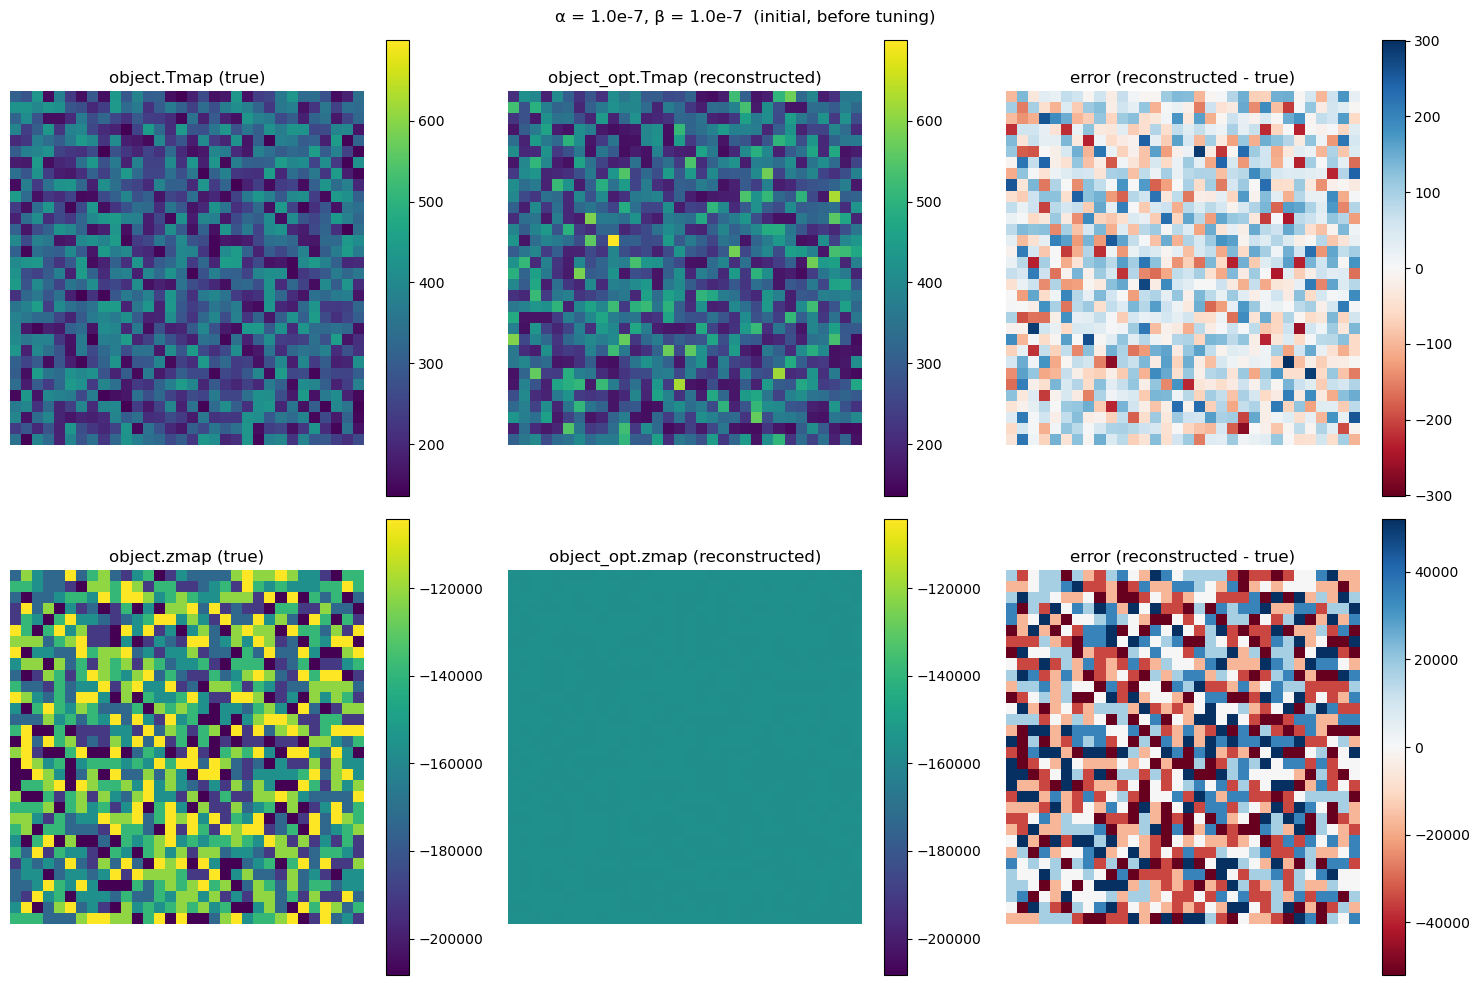

In [12]:
r_init = End2EndThermalImg.reconstruction_error_and_grad(
    out.object, out.noise, α_start, β_start, freqs, weights, driver_plans_PSF, PSF_zcoords, jhp
)
object_opt_init = r_init.object_opt

error_T_init = object_opt_init.Tmap .- out.object.Tmap
error_z_init = object_opt_init.zmap .- out.object.zmap

fig, axes = subplots(2, 3; figsize=(15, 10))

vlims_T = extrema(vcat(vec(out.object.Tmap), vec(object_opt_init.Tmap)))
im00 = axes[0,0].imshow(out.object.Tmap; vmin=vlims_T[1], vmax=vlims_T[2])
axes[0,0].set_title("object.Tmap (true)")
fig.colorbar(im00, ax=axes[0,0])

im01 = axes[0,1].imshow(object_opt_init.Tmap; vmin=vlims_T[1], vmax=vlims_T[2])
axes[0,1].set_title("object_opt.Tmap (reconstructed)")
fig.colorbar(im01, ax=axes[0,1])

elim_T = maximum(abs, error_T_init)
im02 = axes[0,2].imshow(error_T_init; cmap="RdBu", vmin=-elim_T, vmax=elim_T)
axes[0,2].set_title("error (reconstructed - true)")
fig.colorbar(im02, ax=axes[0,2])

vlims_z = extrema(vcat(vec(out.object.zmap), vec(object_opt_init.zmap)))
im10 = axes[1,0].imshow(out.object.zmap; vmin=vlims_z[1], vmax=vlims_z[2])
axes[1,0].set_title("object.zmap (true)")
fig.colorbar(im10, ax=axes[1,0])

im11 = axes[1,1].imshow(object_opt_init.zmap; vmin=vlims_z[1], vmax=vlims_z[2])
axes[1,1].set_title("object_opt.zmap (reconstructed)")
fig.colorbar(im11, ax=axes[1,1])

elim_z = maximum(abs, error_z_init)
im12 = axes[1,2].imshow(error_z_init; cmap="RdBu", vmin=-elim_z, vmax=elim_z)
axes[1,2].set_title("error (reconstructed - true)")
fig.colorbar(im12, ax=axes[1,2])

for ax in axes.flat
    ax.axis("off")
end
fig.suptitle("α = $(α_start), β = $(β_start)  (initial, before tuning)")
fig.tight_layout()
fig;

## Reconstruction of the sampled object at the resolved `α`/`β`

`out.object`/`out.object_opt` are the fixed object the sweep evaluated every candidate against, and
its reconstruction at the final resolved `(α, β)` (a fresh evaluation, not reused from partway
through the search, so it's guaranteed to correspond exactly to `out.α`/`out.β`).

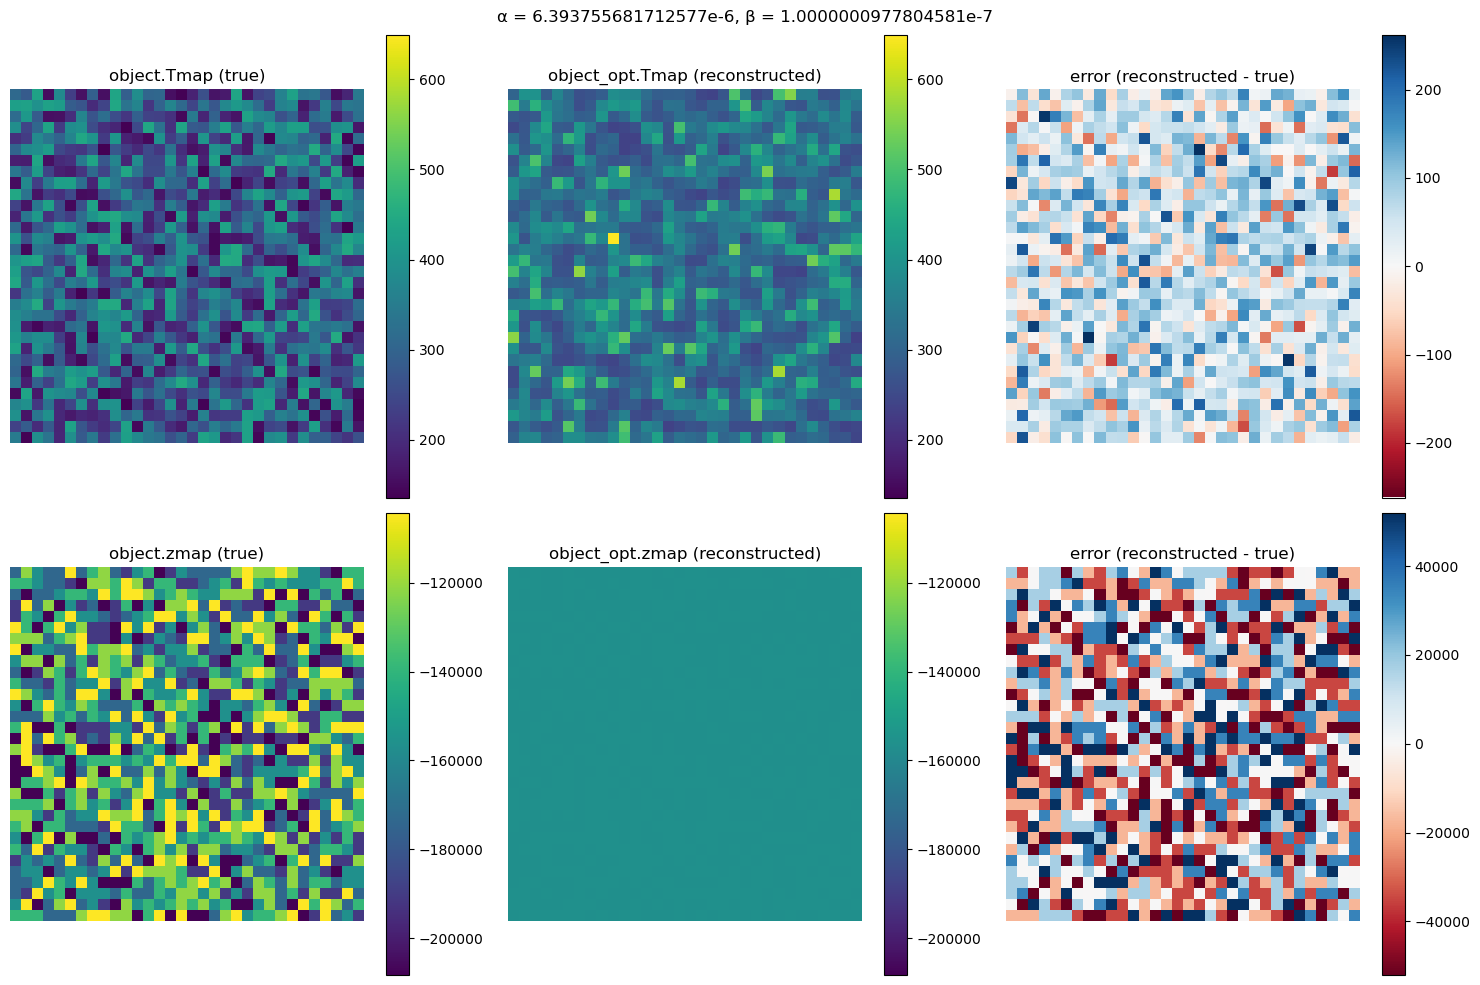

In [13]:
object = out.object
object_opt = out.object_opt
error_T = object_opt.Tmap .- object.Tmap
error_z = object_opt.zmap .- object.zmap

fig, axes = subplots(2, 3; figsize=(15, 10))

vlims_T = extrema(vcat(vec(object.Tmap), vec(object_opt.Tmap)))
im00 = axes[0,0].imshow(object.Tmap; vmin=vlims_T[1], vmax=vlims_T[2])
axes[0,0].set_title("object.Tmap (true)")
fig.colorbar(im00, ax=axes[0,0])

im01 = axes[0,1].imshow(object_opt.Tmap; vmin=vlims_T[1], vmax=vlims_T[2])
axes[0,1].set_title("object_opt.Tmap (reconstructed)")
fig.colorbar(im01, ax=axes[0,1])

elim_T = maximum(abs, error_T)
im02 = axes[0,2].imshow(error_T; cmap="RdBu", vmin=-elim_T, vmax=elim_T)
axes[0,2].set_title("error (reconstructed - true)")
fig.colorbar(im02, ax=axes[0,2])

vlims_z = extrema(vcat(vec(object.zmap), vec(object_opt.zmap)))
im10 = axes[1,0].imshow(object.zmap; vmin=vlims_z[1], vmax=vlims_z[2])
axes[1,0].set_title("object.zmap (true)")
fig.colorbar(im10, ax=axes[1,0])

im11 = axes[1,1].imshow(object_opt.zmap; vmin=vlims_z[1], vmax=vlims_z[2])
axes[1,1].set_title("object_opt.zmap (reconstructed)")
fig.colorbar(im11, ax=axes[1,1])

elim_z = maximum(abs, error_z)
im12 = axes[1,2].imshow(error_z; cmap="RdBu", vmin=-elim_z, vmax=elim_z)
axes[1,2].set_title("error (reconstructed - true)")
fig.colorbar(im12, ax=axes[1,2])

# axes.flat, not axes: subplots(2, 3) returns axes as a 2D numpy array, and iterating a 2D array
# yields its rows (1D sub-arrays), not individual Axes objects -- .flat is numpy's flat iterator,
# which yields each element.
for ax in axes.flat
    ax.axis("off")
end
fig.suptitle("α = $(out.α), β = $(out.β)")
fig.tight_layout()
fig;